# PEtracer lineage tracing (M2-1): s recovers tumour clones the model never saw

Control = the section's non-tumour cells, condition = malignant cells inside tumours (halo cells are
neighbour-only). Lineage (clone, subclade, fitness from the PEtracer barcode trees) is never given to the model.
Held-out clone classification (multinomial logistic, GroupKFold over 150 um spatial blocks), balanced accuracy:

| test | chance | z | s | scVI |
|---|---|---|---|---|
| T1 clone across tumours | 0.17 | 0.41 | **0.65** | 0.63 |
| T2 clone 2-1 vs 2-2 within tumour 2 | 0.50 | 0.78 | **0.80** | 0.77 |
| T3 subclade within clone 5 | 0.07 | 0.11 | **0.14** | 0.12 |
| T4 fitness within clone 5 (R2) | 0 | 0.06 | **0.18** | 0.12 |

In [1]:
import sys; sys.path.insert(0, '/home/yancui/haruka_v2/notebooks')
from repro import run, require, show, STAGES, H, PY
# Default: figure stage only (redraw from saved analysis outputs). Turn on earlier stages to rerun them.
# Fresh machine: STAGES.update(download=True) fetches the preprocessed inputs (section 0), then fit=True, analysis=True.
# STAGES.update(download=True, fit=True, analysis=True)
print(STAGES)

{'download': False, 'data': False, 'fit': False, 'analysis': False, 'figure': True}


## 0 Preprocessed data (Hugging Face)

Skip the data stage: download the ready-to-fit inputs from [C1vy/haruka_v2_data](https://huggingface.co/datasets/C1vy/haruka_v2_data) and link them to the paths the scripts expect.

In [2]:
# C1vy/haruka_v2_data/05_petracer/petracer_M2-1_lineage.h5ad  ->  bench_petracer_lineage/m2_lineage/petracer_M2-1_lineage.h5ad
DL = H / "hf_data"
run(f'hf download C1vy/haruka_v2_data 05_petracer/petracer_M2-1_lineage.h5ad --repo-type dataset --local-dir {DL} && mkdir -p $(dirname bench_petracer_lineage/m2_lineage/petracer_M2-1_lineage.h5ad) && ln -sfn {DL}/05_petracer/petracer_M2-1_lineage.h5ad bench_petracer_lineage/m2_lineage/petracer_M2-1_lineage.h5ad', 'download')

[skip: download stage off] hf download C1vy/haruka_v2_data 05_petracer/petracer_M2-1_lineage.h5ad --repo-type dataset --local-dir /home/yancui/haruka_v2/hf_data && mkdir -p $(dirname bench_petracer_lineage/m2_lineage/petracer_M2-1_lineage.h5ad) && ln -sfn /home/yancui/haruka_v2/hf_data/05_petracer/petracer_M2-1_lineage.h5ad bench_petracer_lineage/m2_lineage/petracer_M2-1_lineage.h5ad


## 1 Data: tumour vs non-tumour design from the PEtracer release, then the lineage design

In [3]:
run(f'{PY} bench_petracer_lineage/reaudit_2026-10-16/build_m2_tumour_vs_normal.py', 'data', log='bench_petracer_lineage/reaudit_2026-10-16/build_m2.log')
run(f'{PY} build_m2_lineage.py', 'data', cwd=H / 'bench_petracer_lineage/m2_lineage')

[skip: data stage off] /home/yancui/.conda/envs/haruka2/bin/python bench_petracer_lineage/reaudit_2026-10-16/build_m2_tumour_vs_normal.py
[skip: data stage off] /home/yancui/.conda/envs/haruka2/bin/python build_m2_lineage.py


## 2 Haruka fit (~5 min) and the scVI baseline (~20 min)

In [4]:
run('bash run_fit.sh 0', 'fit', cwd=H / 'bench_petracer_lineage/m2_lineage', log='fit.log')
run(f'{PY} fit_scvi.py', 'fit', cwd=H / 'bench_petracer_lineage/m2_lineage', log='scvi.log')

[skip: fit stage off] bash run_fit.sh 0
[skip: fit stage off] /home/yancui/.conda/envs/haruka2/bin/python fit_scvi.py


## 3 Lineage tests T1-T5 (z vs s vs scVI)

In [5]:
run(f'{PY} bench_petracer_lineage/m2_lineage/lineage_test.py', 'analysis', log='bench_petracer_lineage/m2_lineage/lineage_test.out')
import pandas as pd; pd.read_csv(H / 'bench_petracer_lineage/m2_lineage/lineage_test_summary.csv').round(3)

[skip: analysis stage off] /home/yancui/.conda/envs/haruka2/bin/python bench_petracer_lineage/m2_lineage/lineage_test.py


,test,chance,z,s,scVI
0,T1 clone across tumours,0.170,0.413,0.654,0.633
1,T2 clone 2-1 vs 2-2 within tumour 2,0.500,0.775,0.801,0.765
2,T3 subclade within clone 5 (1114 cells),0.071,0.109,0.144,0.123
3,T4 fitness within clone 5 (1169 cells),0.000,0.061,0.176,0.116
4,T5 latent vs lineage distance (Spearman),0.000,-0.030,0.029,0.002
5,"T5 same, partial on spatial distance",0.000,-0.030,0.026,0.001


## 4 Panels and the page

In [6]:
T = H / 'figures_paper/petracer'
run(f'{PY} make_petracer_figure.py', 'figure', cwd=T)
run(f'{PY} ../compose_montage.py petracer', 'figure', cwd=T)

z held-out clone balanced acc 0.413
s held-out clone balanced acc 0.654
                type  r_z_background  r_with_s  gain
     ARG1 macrophage          -0.009     0.535 0.544
    CD11c macrophage           0.191     0.719 0.528
          CD4 T cell           0.228     0.564 0.335
   Cancer fibroblast           0.289     0.524 0.235
         Endothelial           0.088     0.410 0.322
Exhausted CD8 T cell           0.160     0.518 0.358
           Malignant          -0.119     0.780 0.900
fonts: []
[figure] exit 0 in 71s: /home/yancui/.conda/envs/haruka2/bin/python make_petracer_figure.py


wrote /home/yancui/haruka_v2/figures_paper/petracer/PEtracer_full.png
[figure] exit 0 in 2s: /home/yancui/.conda/envs/haruka2/bin/python ../compose_montage.py petracer


## Figure

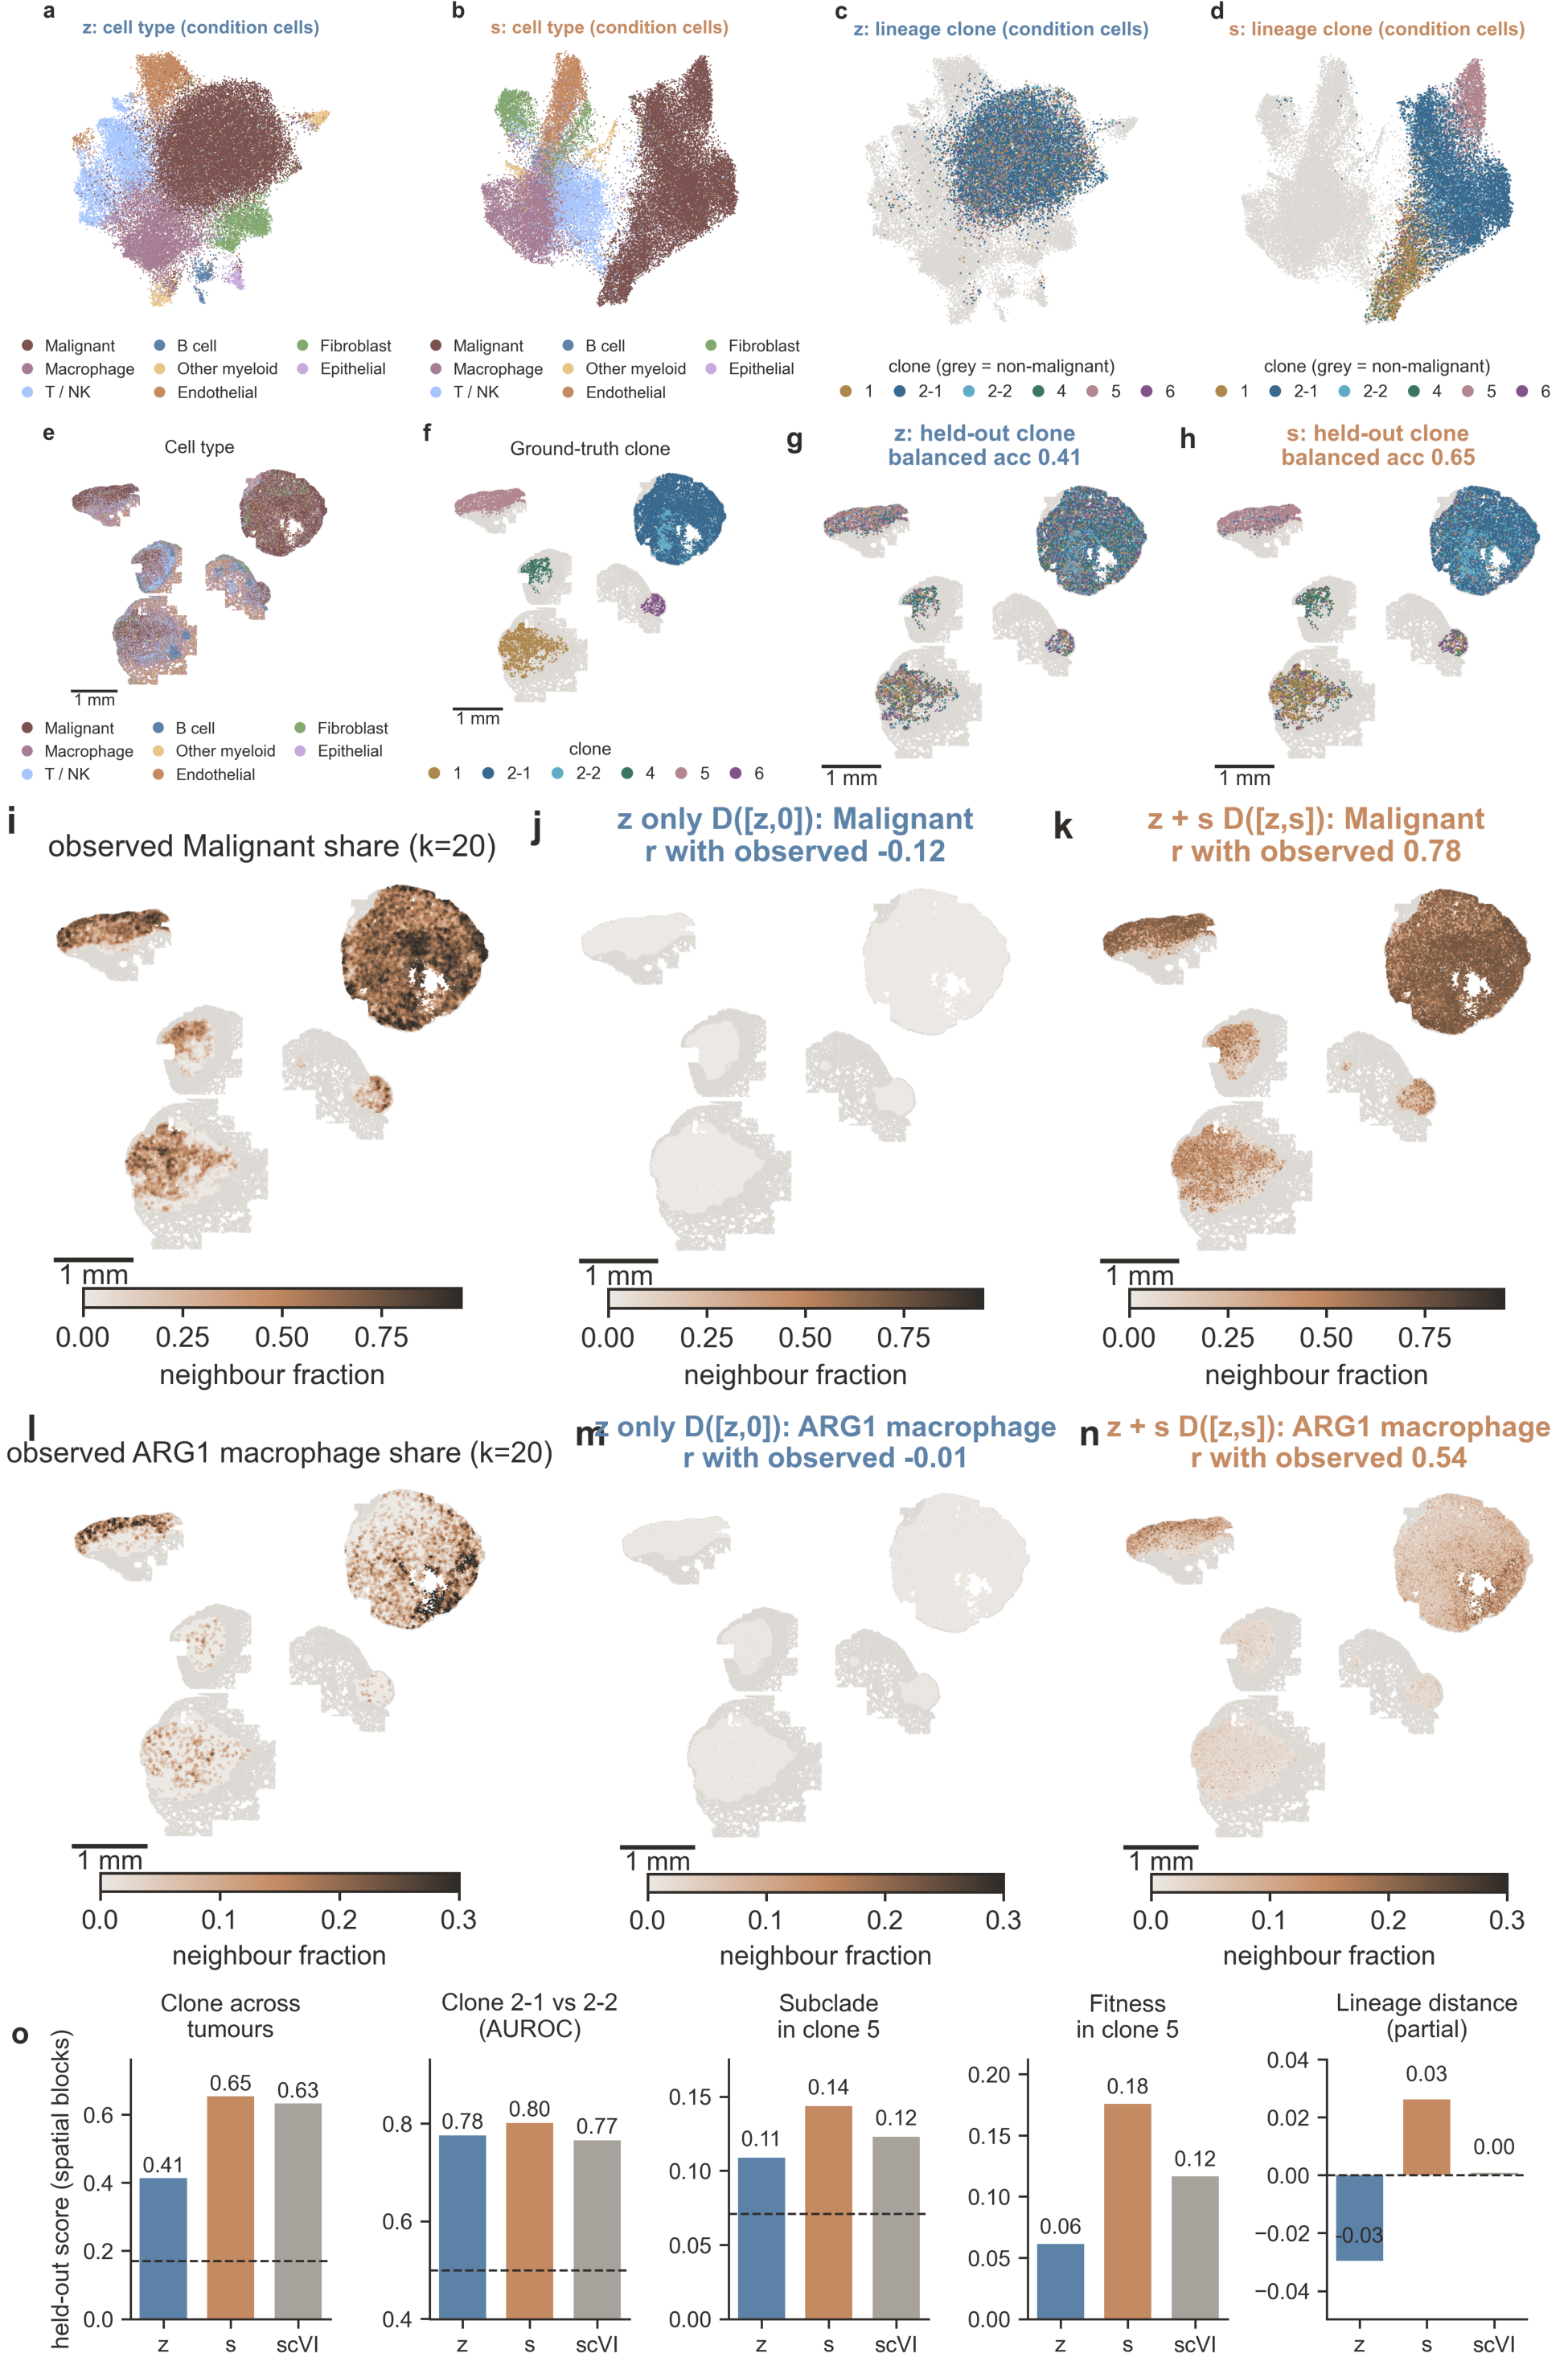

In [7]:
show(H / 'figures_paper/petracer/PEtracer_full.png')